# 01 · Validazione del porting a Geant4 11

**Domanda:** la simulazione JEPO-1.1, portata da Geant4 10 a Geant4 11.4.3 e resa parametrica nella geometria delle barre, riproduce ancora il codice originale e i risultati dell'articolo?

Dati usati (tutti in `~/runs`, 100k eventi per run, seed fissi `1000 + k`):

| cartella | codice | Geant4 | setup |
|---|---|---|---|
| `base_theta`, `base_tb` | originale (solo porting) | 11.4.3 | scan in θ, test beam 2018 |
| `new_theta`, `new_tb` | parametrizzato (`cf372b0`) | 11.4.3 | idem |
| `repro_a`, `repro_b` | parametrizzato, lettura `beam.in` corretta | 11.4.3 | test beam, due volte |
| `g4107_0.22`, `g4107_0.0` | originale | 10.7.4 | test beam, smearing 0.22 e 0 |

L'analisi è `analysis/sith_reco.py`, il porting Python di `Simulation_runner.cpp` + `Peak_fitter.py`: sugli stessi file dà gli stessi numeri degli script ROOT originali (θ: 0.08663° vs 0.0866°; test beam: 1.3028 vs 1.303 mm).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
from compare_ntuples import load as load_events
R = sp.RUNS
geom = sr.Geometry()
pat = lambda d: str(R / d / "output" / "*MeV_t*-{run}.root")
PAPER = dict(sigma_tb_mm=0.911, sigma_tb_data_mm=0.907, sigma_theta_deg=0.0912)

## 1. Riproducibilità evento per evento

Con lo stesso seed, Geant4 multi-thread genera ogni evento in modo identico indipendentemente dal thread che lo processa. Il confronto è fatto per `eventID`, colonna per colonna.

In [2]:
def identical(a, b, run):
    A, B = load_events(str(R / a), run), load_events(str(R / b), run)
    return all(np.array_equal(A[k], B[k], equal_nan=True) for k in A)

checks = [("scan θ: originale vs parametrizzato", "base_theta", "new_theta", [0, 12, 25]),
          ("test beam: originale, due run con stesso seed", "base_tb", "base_tb2", [3]),
          ("test beam: parametrizzato + beam.in corretto, due run", "repro_a", "repro_b", [0, 3, 6])]
rows = [dict(confronto=c, run=str(runs), identici=all(identical(a, b, r) for r in runs)) for c, a, b, runs in checks]
pd.DataFrame(rows)

,confronto,run,identici
0,scan θ: originale vs parametrizzato,"[0, 12, 25]",True
1,"test beam: originale, due run con stesso seed",[3],False
2,"test beam: parametrizzato + beam.in corretto, ...","[0, 3, 6]",True


Il codice parametrizzato con la geometria di default è **identico bit a bit** all'originale. Il test beam originale invece *non* era riproducibile: ogni thread leggeva `beam.in` riga per riga e la riga usata da un evento dipendeva da quale thread aveva processato l'evento 0. Ora `beam.in` è letto una volta e indicizzato per `eventID`.

## 2. Scan in θ (rivelatore completo, configurazione PERPENDICULAR)

26 run a θ fisso da 5° a 17.5°, φ uniforme. La distribuzione di θ ricostruito è l'istogramma `HTh` di `Simulation_runner.cpp` (bin da 0.05°).

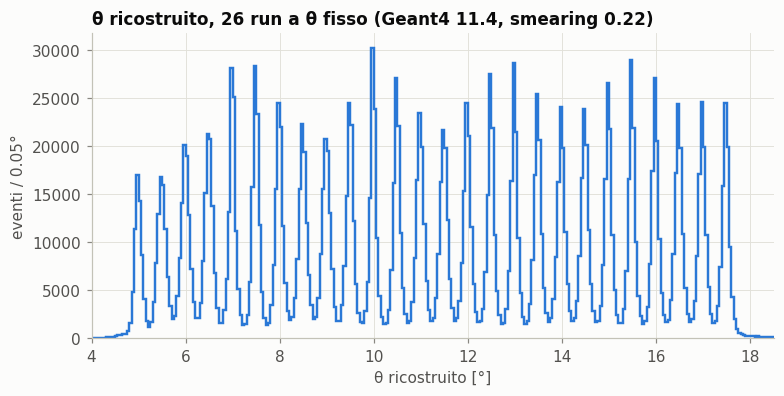

In [3]:
th = sr.analyse_theta(pat("base_theta"), 26, geom)
per_run = pd.DataFrame(th["per_run"])
all_theta = []
for k in range(26):
    F, B, _ = sr.load(sr.run_files(pat("base_theta"), k), geom)
    all_theta.append(sr.reconstruct(F, B, geom)["theta"])
all_theta = np.concatenate(all_theta)

fig, ax = plt.subplots(figsize=(8, 3.6))
sp.hist_line(ax, all_theta, 400, (0, 20), sp.SERIES[0])
ax.set(xlim=(4, 18.5), xlabel="θ ricostruito [°]", ylabel="eventi / 0.05°",
       title="θ ricostruito, 26 run a θ fisso (Geant4 11.4, smearing 0.22)")
plt.show()

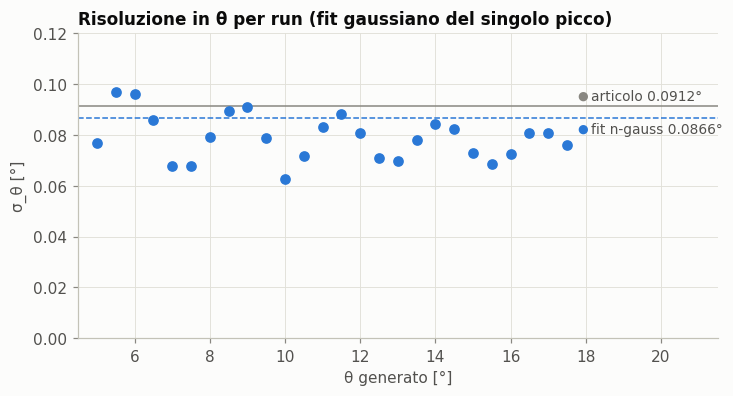

fit n-gaussiane (procedura di Peak_fitter.py): 0.0866 ± 0.0002°  (χ²/ndf 251);  media dei fit per run: 0.0790°


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(per_run.theta_gen, per_run.sigma, per_run.sigma_err, fmt="o", color=sp.SERIES[0], ms=6)
ax.axhline(th["multi_sigma_mean"], color=sp.SERIES[0], lw=1, ls="--")
ax.axhline(PAPER["sigma_theta_deg"], color=sp.MUTED, lw=1)
sp.end_label(ax, 17.6, th["multi_sigma_mean"], f"fit n-gauss {th['multi_sigma_mean']:.4f}°", sp.SERIES[0], dy=-7)
sp.end_label(ax, 17.6, PAPER["sigma_theta_deg"], "articolo 0.0912°", sp.MUTED, dy=7)
ax.set(xlim=(4.5, 21.5), ylim=(0, 0.12), xlabel="θ generato [°]", ylabel="σ_θ [°]",
       title="Risoluzione in θ per run (fit gaussiano del singolo picco)")
plt.show()
print(f"fit n-gaussiane (procedura di Peak_fitter.py): {th['multi_sigma_mean']:.4f} ± {th['multi_sigma_err_mean']:.4f}°  "
      f"(χ²/ndf {th['multi_chi2ndf']:.0f});  media dei fit per run: {th['sigma_mean']:.4f}°")

Il fit a n gaussiane dello stesso istogramma (procedura dell'articolo) dà **0.0866°** contro 0.0912° dell'articolo: 5% in meno. Il χ²/ndf molto alto dice che i picchi non sono gaussiani (code) e che i bin da 0.05° sono larghi rispetto a σ (si vede l'aliasing nell'altezza dei picchi), quindi il numero dipende dalla procedura; la differenza con l'articolo potrebbe venire da una versione diversa di `Simulation_runner.cpp` (l'ultimo commit, "angular correction", è del 28/10/2021).

## 3. Test beam 2018 (configurazione PARALLEL)

Due strati paralleli da 3 moduli; lo strato posteriore è traslato in 7 step (~4.78 mm). L'*offset* è η_F − η_B per la coppia di moduli (3, 11); la sua larghezza, calibrata in mm con la distanza tra il primo e l'ultimo picco, è la risoluzione riportata.

Lo step 0 non è gaussiano: lì il fascio colpisce lo strato posteriore a cavallo di due coppie di moduli ((3,11) e (3,10), circa 60/40), e la coda a destra viene dagli eventi della seconda coppia. È una caratteristica del setup, presente anche nel codice originale.

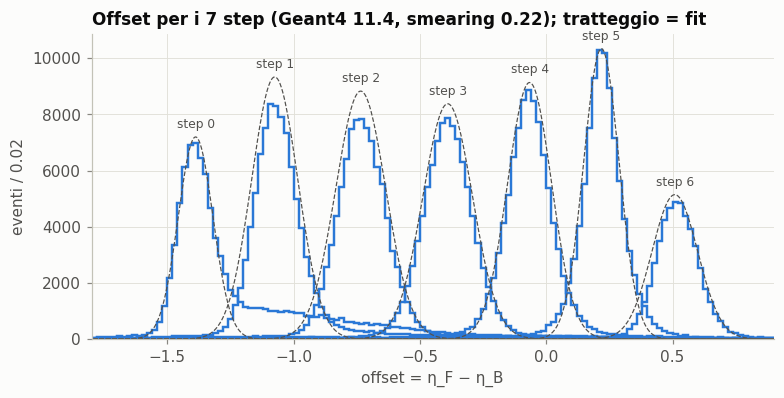

In [5]:
def tb_offsets(d):
    out = []
    for k in range(7):
        F, B, _ = sr.load(sr.run_files(pat(d), k), geom, extra=())
        qF, rF, eF = sr.select_pairs(F, 7); qB, rB, eB = sr.select_pairs(B, 7)
        m = (qF == 3) & (rF == 11) & (qB >= 0)
        out.append(eF[m] - eB[m])
    return out

tb11, tb107 = sr.analyse_tb(pat("repro_a"), 7, geom), sr.analyse_tb(pat("g4107_0.22"), 7, geom)
offs = tb_offsets("repro_a")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.linspace(-2, 2, 800)
for k, o in enumerate(offs):
    sp.hist_line(ax, o, 200, (-2, 2), sp.SERIES[0])
    s = tb11["sigma_mm"][k] / tb11["calib_mm_per_offset"]; mu = tb11["means"][k]; a = tb11["amplitudes"][k]
    ax.plot(x, a * np.exp(-0.5 * ((x - mu) / s) ** 2), color=sp.INK2, lw=0.8, ls="--")
    ax.annotate(f"step {k}", (mu, max(a, np.histogram(o, 200, (-2, 2))[0].max())), xytext=(0, 6),
                textcoords="offset points", ha="center", color=sp.INK2, fontsize=8)
ax.set(xlim=(-1.8, 0.9), xlabel="offset = η_F − η_B", ylabel="eventi / 0.02",
       title="Offset per i 7 step (Geant4 11.4, smearing 0.22); tratteggio = fit")
plt.show()

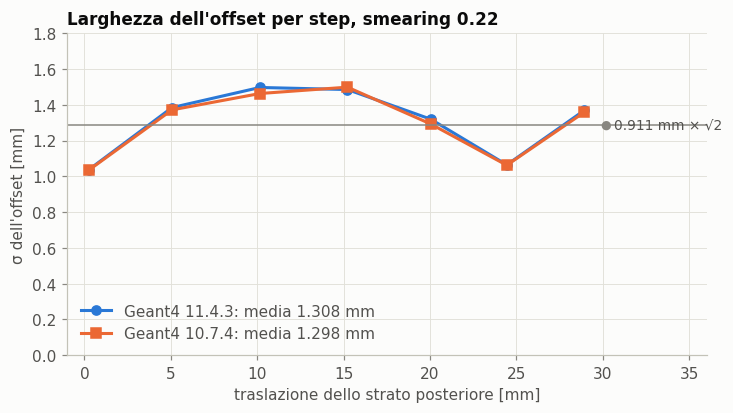

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
xs = np.array(sr.TB_TRANSLATE)
for res, lab, c, mk in ((tb11, "Geant4 11.4.3", sp.SERIES[0], "o"), (tb107, "Geant4 10.7.4", sp.SERIES[1], "s")):
    ax.plot(xs, res["sigma_mm"], marker=mk, color=c, label=f"{lab}: media {res['sigma_mm_mean']:.3f} mm")
ref = PAPER["sigma_tb_mm"] * np.sqrt(2)
ax.axhline(ref, color=sp.MUTED, lw=1)
sp.end_label(ax, 29.5, ref, "0.911 mm × √2", sp.MUTED)
ax.set(xlim=(-1, 36), ylim=(0, 1.8), xlabel="traslazione dello strato posteriore [mm]",
       ylabel="σ dell'offset [mm]", title="Larghezza dell'offset per step, smearing 0.22")
ax.legend(loc="lower left")
plt.show()

In [7]:
rows = []
for lab, d in (("Geant4 11.4.3, smearing 0.22", "repro_a"), ("Geant4 10.7.4, smearing 0.22", "g4107_0.22"),
               ("Geant4 11.4.3, smearing 0", "const_0.0"), ("Geant4 10.7.4, smearing 0", "g4107_0.0")):
    r = sr.analyse_tb(pat(d), 7, geom)
    rows.append({"simulazione": lab, "σ offset [mm]": round(r["sigma_mm_mean"], 3),
                 "± [mm]": round(r["sigma_mm_err_mean"], 3), "σ / √2 [mm]": round(r["sigma_mm_mean"] / np.sqrt(2), 3)})
rows.append({"simulazione": "articolo: G4 (dE = 0.22)", "σ offset [mm]": None, "± [mm]": 0.003, "σ / √2 [mm]": None,
             "valore citato [mm]": 0.911})
rows.append({"simulazione": "articolo: dati TB 2018", "σ offset [mm]": None, "± [mm]": 0.003, "σ / √2 [mm]": None,
             "valore citato [mm]": 0.907})
pd.DataFrame(rows)

,simulazione,σ offset [mm],± [mm],σ / √2 [mm],valore citato [mm]
0,"Geant4 11.4.3, smearing 0.22",1.308,0.008,0.925,NaN
1,"Geant4 10.7.4, smearing 0.22",1.298,0.008,0.918,NaN
2,"Geant4 11.4.3, smearing 0",0.795,0.002,0.562,NaN
3,"Geant4 10.7.4, smearing 0",0.768,0.002,0.543,NaN
4,articolo: G4 (dE = 0.22),NaN,0.003,NaN,0.911
5,articolo: dati TB 2018,NaN,0.003,NaN,0.907


**Lettura.**

* La versione di Geant4 non conta: 10.7.4 e 11.4.3 differiscono di meno del 3% (anche con smearing 0, cioè solo fisica).
* Con smearing 0.22 la larghezza dell'offset è ~1.30 mm; divisa per √2 dà ~0.92 mm, a ~1% dal 0.911 dell'articolo. `Peak_fitter.py` riporta la larghezza intera, quindi il valore dell'articolo sembra essere quello **per strato** (offset / √2): andrebbe scritto esplicitamente nel testo, per G4 e per i dati.
* Lo smearing 0.22 era stato tarato per far coincidere le gaussiane simulate con quelle misurate: poiché le distribuzioni simulate sono le stesse del 2021, **la taratura 0.22 resta valida** ed è il riferimento per il modello fotostatistico (notebook 02).